In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
plt.rcParams['figure.figsize'] = (10,4)

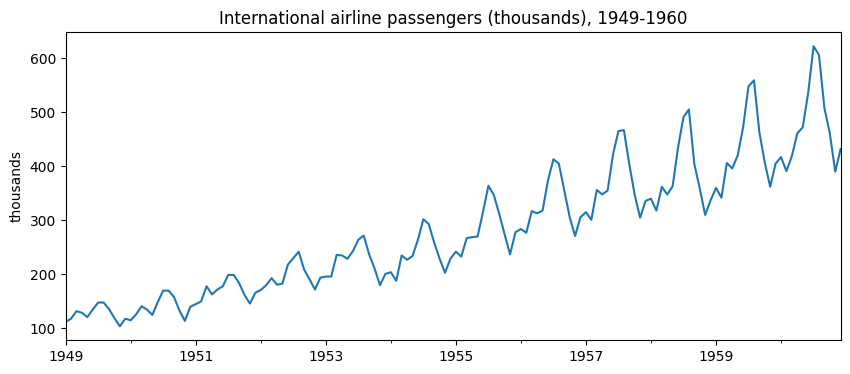

In [3]:
import seaborn as sns
flights = sns.load_dataset('flights')
y = pd.Series(flights['passengers'].values,
              index=pd.date_range('1949-01-01', periods=144, freq='MS'), name='passengers')
assert len(y) == 144 and y.sum() == 40363
y.plot(title='International airline passengers (thousands), 1949-1960'); plt.ylabel('thousands'); plt.show()

In [5]:
train, test = y[:'1958'], y['1959':]
H = len(test)
print(f'train: {len(train)} months ({train.index[0]:%b %Y} - {train.index[-1]:%b %Y})')
print(f'train: {len(test)} months ({train.index[0]:%b %Y} - {train.index[-1]:%b %Y})')
print(f'max passengers in train: {train.max()} max in test {test.max()}')

def rmse(f,a): return float(np.sqrt(np.mean((np.asarray(f, float) - np.asarray(a, float))**2)))
def mape(f,a): return float(100*np.mean(np.abs(np.asarray(f, float) - np.asarray(a, float))/np.abs(np.asarray(a, float))))
results = {}

train: 120 months (Jan 1949 - Dec 1958)
train: 24 months (Jan 1949 - Dec 1958)
max passengers in train: 505 max in test 622


In [9]:
snaive = np.tile(train.values[-12:],2)
results['Seasonal naive'] = (rmse(snaive, test), mape(snaive, test))
print('Seasonal naive RMSE %.1f MAPE %.1f%%' % results['Seasonal naive'])

Seasonal naive RMSE 77.0 MAPE 15.5%


In [11]:
def make_windows(s,p):
  s = np.asarray(s,float)
  X = np.array([s[i - p:i] for i in range(p, len(s))])
  return X, s[p:]

def recursive_forecast(model, history, p, h):
  hist = list(np.asarray(history, float))
  out = []
  for _ in range(h):
    nxt = float(model.predict(np.array(hist[-p:]).reshape(1,-1))[0])
    out.append(nxt); hist.append(nxt)
  return np.array(out)

X_demo, t_demo = make_windows(np.arange(1,8), 3)
print(X_demo, t_demo)

[[1. 2. 3.]
 [2. 3. 4.]
 [3. 4. 5.]
 [4. 5. 6.]] [4. 5. 6. 7.]
